# Atividade de Análise de Dados e BI - Mobilidade Urbana

**Instituição:** Faculdade SENAI Fatesg<br>
**Curso:** Tecnologia em Inteligência Artificial<br>
**Disciplina:** Inteligência de Negócios (Business Intelligence)<br>
**Professor:** Me. Ujeverson Tavares

**Equipe:**
* Marcus
* Patricia Andrade Belo
* Paulo
* Pietro Borges Gama

---

In [1]:
# Importando as Bibliotecas que serão necessárias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [9]:
# Importando o Dataset
# O parâmetro 'encoding' e 'sep' garantem que os caracteres e separadores sejam lidos corretamente
df1 = pd.read_csv('mobilidade_urbana.csv', encoding='utf-8', sep=';')

# Exibe as 5 primeiras linhas do DataFrame para entender a estrutura dos dados
df1.head()

,Localidade,Variável,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Aparecida de Goiânia,Frota de Veículos - Ônibus (número),595,613,666,709,732,712,750,751,799,837,873
1,Aparecida de Goiânia,População Estimada - Total (habitantes),521.910,532.135,542.090,565.957,578.179,590.146,601.844,500.760,527.796,550.925,556.021
2,Goiânia,Frota de Veículos - Ônibus (número),6.607,6.733,6.742,6.767,7.118,7.015,7.192,7.354,7.626,8.039,8.006
3,Goiânia,População Estimada - Total (habitantes),1.430.697,1.448.639,1.466.105,1.495.705,1.516.113,1.536.097,1.555.626,1.414.483,1.437.366,1.494.599,1.503.256
4,Senador Canedo,Frota de Veículos - Ônibus (número),93,91,117,125,123,129,136,128,143,143,143


In [11]:
df1.columns

Index(['Localidade', 'Variável', '2015', '2016', '2017', '2018', '2019',
       '2020', '2021', '2022', '2023', '2024', '2025'],
      dtype='str')

In [12]:
df1.describe()

,Localidade,Variável,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
count,6,6,6,6,6,6,6,6,6,6,6,6,6
unique,3,2,6,6,6,6,6,6,6,6,6,6,6
top,Aparecida de Goiânia,Frota de Veículos - Ônibus (número),595,613,666,709,732,712,750,751,799,837,873
freq,2,3,1,1,1,1,1,1,1,1,1,1,1


In [13]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Localidade  6 non-null      str  
 1   Variável    6 non-null      str  
 2   2015        6 non-null      str  
 3   2016        6 non-null      str  
 4   2017        6 non-null      str  
 5   2018        6 non-null      str  
 6   2019        6 non-null      str  
 7   2020        6 non-null      str  
 8   2021        6 non-null      str  
 9   2022        6 non-null      str  
 10  2023        6 non-null      str  
 11  2024        6 non-null      str  
 12  2025        6 non-null      str  
dtypes: str(13)
memory usage: 756.0 bytes


In [14]:
df1.isnull().sum()

Localidade    0
Variável      0
2015          0
2016          0
2017          0
2018          0
2019          0
2020          0
2021          0
2022          0
2023          0
2024          0
2025          0
dtype: int64

In [15]:
# 1. Transformar as colunas de anos em uma única coluna 'Ano' (facilita muito os gráficos)
df1_melt = df1.melt(id_vars=['Localidade', 'Variável'], var_name='Ano', value_name='Valor')

# 2. Limpeza: remover os pontos que indicam milhar e converter a coluna para valores numéricos
df1_melt['Valor'] = df1_melt['Valor'].astype(str).str.replace('.', '', regex=False)
df1_melt['Valor'] = pd.to_numeric(df1_melt['Valor'], errors='coerce')

# 3. Separar em duas tabelas para calcular os KPIs facilmente
df_frota = df1_melt[df1_melt['Variável'] == 'Frota de Veículos - Ônibus (número)'].copy()
df_populacao = df1_melt[df1_melt['Variável'] == 'População Estimada - Total (habitantes)'].copy()

# Visualizando como a tabela ficou estruturada agora para a análise
df1_melt.head()

,Localidade,Variável,Ano,Valor
0,Aparecida de Goiânia,Frota de Veículos - Ônibus (número),2015,595
1,Aparecida de Goiânia,População Estimada - Total (habitantes),2015,521910
2,Goiânia,Frota de Veículos - Ônibus (número),2015,6607
3,Goiânia,População Estimada - Total (habitantes),2015,1430697
4,Senador Canedo,Frota de Veículos - Ônibus (número),2015,93


### KPI 1: Crescimento Percentual da Frota de Ônibus (2015 vs. 2025)
**O que faz:** Calcula a variação percentual do volume de veículos de transporte coletivo disponíveis, comparando diretamente o primeiro e o último ano da série histórica.
**Objetivo:** Avaliar o esforço real de expansão da infraestrutura urbana. Permite validar estrategicamente se as cidades investiram no aumento da sua frota ao longo da década ou se a oferta estagnou.

In [16]:
# 1. Filtramos apenas os anos inicial (2015) e final (2025) da tabela de frota
df_kpi1 = df_frota[df_frota['Ano'].isin(['2015', '2025'])].copy()

# 2. Reorganizamos a tabela para colocar os anos como colunas (lado a lado)
df_kpi1_pivot = df_kpi1.pivot(index='Localidade', columns='Ano', values='Valor')

# 3. Aplicamos a fórmula: ((Valor Final - Valor Inicial) / Valor Inicial) * 100
df_kpi1_pivot['Crescimento Frota (%)'] = ((df_kpi1_pivot['2025'] - df_kpi1_pivot['2015']) / df_kpi1_pivot['2015']) * 100

# 4. Arredondamos para 2 casas decimais para melhorar a visualização
df_kpi1_pivot = df_kpi1_pivot.round(2)

print("--- KPI 1: Crescimento da Frota (2015 - 2025) ---")
df_kpi1_pivot

--- KPI 1: Crescimento da Frota (2015 - 2025) ---


Ano,2015,2025,Crescimento Frota (%)
Localidade,,,
Aparecida de Goiânia,595,873,46.72
Goiânia,6607,8006,21.17
Senador Canedo,93,143,53.76


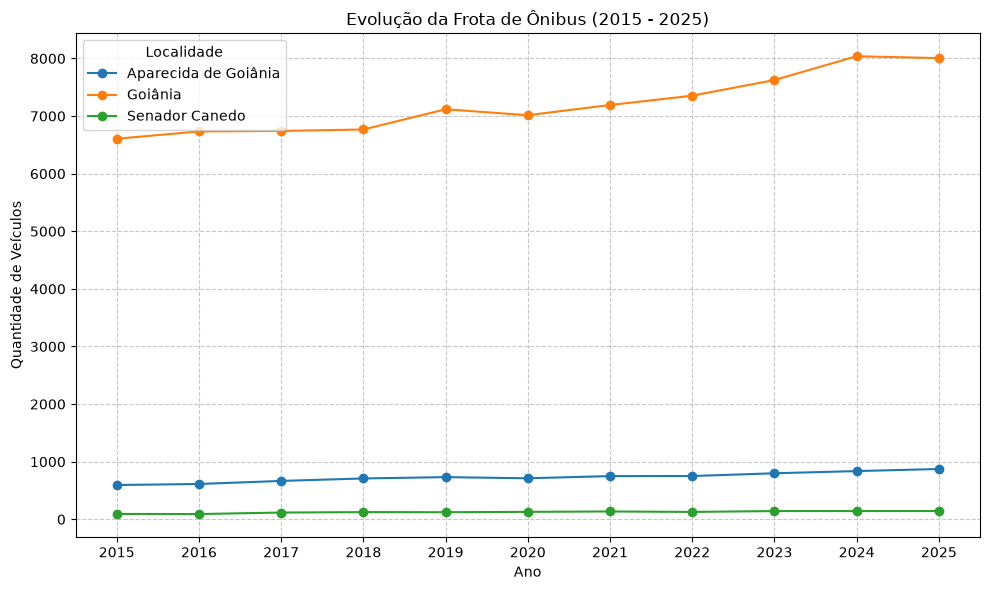

In [21]:
# 1. Reorganizamos a tabela da frota para que os anos sejam o eixo X (índice) 
# e as cidades sejam colunas individuais
df_evolucao_frota = df_frota.pivot(index='Ano', columns='Localidade', values='Valor')

# 2. Configurar o tamanho da figura
plt.figure(figsize=(10, 6))

# 3. Desenhar uma linha para cada cidade na tabela
for cidade in df_evolucao_frota.columns:
    plt.plot(df_evolucao_frota.index, df_evolucao_frota[cidade], marker='o', label=cidade)

# 4. Adicionar as formatações para deixar o gráfico profissional (títulos, grelha, legenda)
plt.title('Evolução da Frota de Ônibus (2015 - 2025)')
plt.xlabel('Ano')
plt.ylabel('Quantidade de Veículos')
plt.grid(True, linestyle='--', alpha=0.7) # Adiciona uma grelha de fundo
plt.legend(title='Localidade') # Mostra a legenda das cores

# 5. Mostrar o gráfico
plt.tight_layout()
plt.show()

### KPI 2: Taxa de Habitantes por Ônibus (Nível de Saturação)
**O que faz:** Cruza a demanda com a oferta, dividindo a população estimada de cada cidade pelo número de ônibus disponíveis em cada ano analisado.

**Objetivo:** Medir a sobrecarga e a qualidade do sistema de transporte. Se a taxa sobe ao longo do tempo, significa que o crescimento demográfico engoliu a infraestrutura existente, revelando perda de eficiência e potencial superlotação para os passageiros.

In [18]:
# 1. Juntar as tabelas de população e frota usando a Localidade e o Ano como referência
df_kpi2 = pd.merge(df_populacao[['Localidade', 'Ano', 'Valor']], 
                   df_frota[['Localidade', 'Ano', 'Valor']], 
                   on=['Localidade', 'Ano'], 
                   suffixes=('_Pop', '_Frota'))

# 2. Calcular o rácio de habitantes por veículo
df_kpi2['Habitantes por Ônibus'] = df_kpi2['Valor_Pop'] / df_kpi2['Valor_Frota']

# 3. Arredondar para o número inteiro mais próximo (representando pessoas inteiras)
df_kpi2['Habitantes por Ônibus'] = df_kpi2['Habitantes por Ônibus'].round(0).astype(int)

# 4. Reorganizar a tabela para visualizar a evolução anual lado a lado
df_kpi2_pivot = df_kpi2.pivot(index='Localidade', columns='Ano', values='Habitantes por Ônibus')

print("--- KPI 2: Habitantes por Ônibus (2015 - 2025) ---")
df_kpi2_pivot

--- KPI 2: Habitantes por Ônibus (2015 - 2025) ---


Ano,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Localidade,,,,,,,,,,,
Aparecida de Goiânia,877,868,814,798,790,829,802,667,661,658,637
Goiânia,217,215,217,221,213,219,216,192,188,186,188
Senador Canedo,1079,1131,901,898,938,918,893,1199,1088,1188,1224


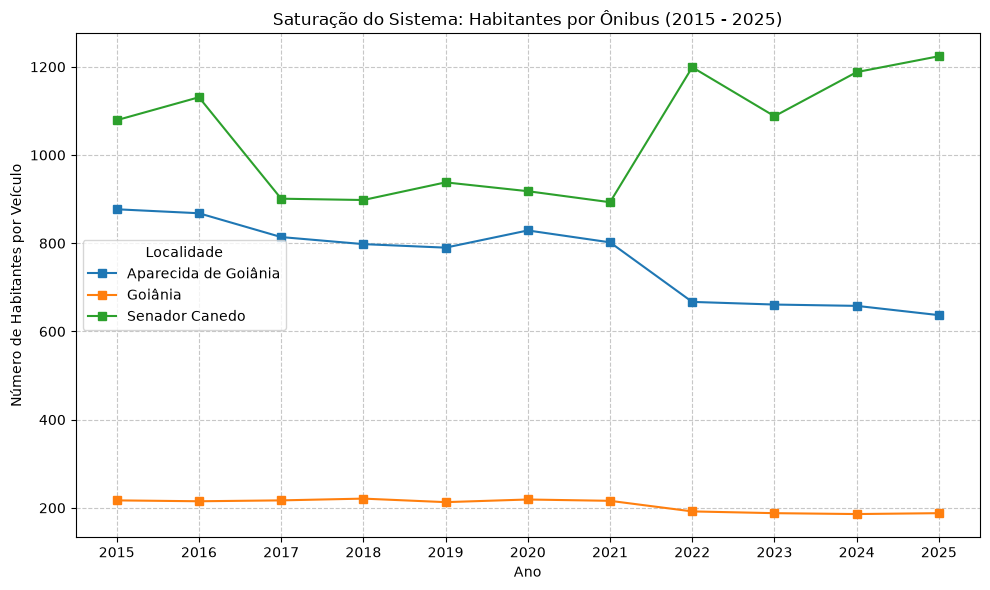

In [22]:
# 1. Preparar os dados: reorganizar para que os anos fiquem no eixo X
df_kpi2_pivot_grafico = df_kpi2.pivot(index='Ano', columns='Localidade', values='Habitantes por Ônibus')

# 2. Configurar o tamanho da figura
plt.figure(figsize=(10, 6))

# 3. Desenhar as linhas para cada cidade (usando o marcador 's' de square/quadrado)
for cidade in df_kpi2_pivot_grafico.columns:
    plt.plot(df_kpi2_pivot_grafico.index, df_kpi2_pivot_grafico[cidade], marker='s', label=cidade)

# 4. Formatação e títulos
plt.title('Saturação do Sistema: Habitantes por Ônibus (2015 - 2025)')
plt.xlabel('Ano')
plt.ylabel('Número de Habitantes por Veículo')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Localidade')

# 5. Exibir gráfico
plt.tight_layout()
plt.show()

### KPI 3: Share da Frota na Região Metropolitana (2025)
**O que faz:** Determina a fatia percentual que a frota de cada município representa em relação ao volume total de veículos das três cidades no ano mais recente.

**Objetivo:** Evidenciar o nível de centralização dos recursos de mobilidade. Serve para mapear a dependência estrutural das cidades vizinhas face à capital e analisar a distribuição do poder de transporte na região metropolitana.

In [19]:
# 1. Filtramos os dados da frota apenas para o ano mais recente (2025)
df_kpi3 = df_frota[df_frota['Ano'] == '2025'].copy()

# 2. Calculamos o total de ônibus nas 3 cidades analisadas
total_frota = df_kpi3['Valor'].sum()

# 3. Calculamos a fatia (Share) de cada cidade em relação a esse total
df_kpi3['Share da Frota (%)'] = (df_kpi3['Valor'] / total_frota) * 100

# 4. Arredondamos para 2 casas decimais e organizamos do maior para o menor
df_kpi3['Share da Frota (%)'] = df_kpi3['Share da Frota (%)'].round(2)
df_kpi3 = df_kpi3.sort_values(by='Share da Frota (%)', ascending=False)

# Exibimos apenas as colunas essenciais para o resultado
print(f"--- KPI 3: Share da Frota em 2025 (Total Região: {total_frota} veículos) ---")
df_kpi3[['Localidade', 'Valor', 'Share da Frota (%)']]

--- KPI 3: Share da Frota em 2025 (Total Região: 9022 veículos) ---


,Localidade,Valor,Share da Frota (%)
62,Goiânia,8006,88.74
60,Aparecida de Goiânia,873,9.68
64,Senador Canedo,143,1.59


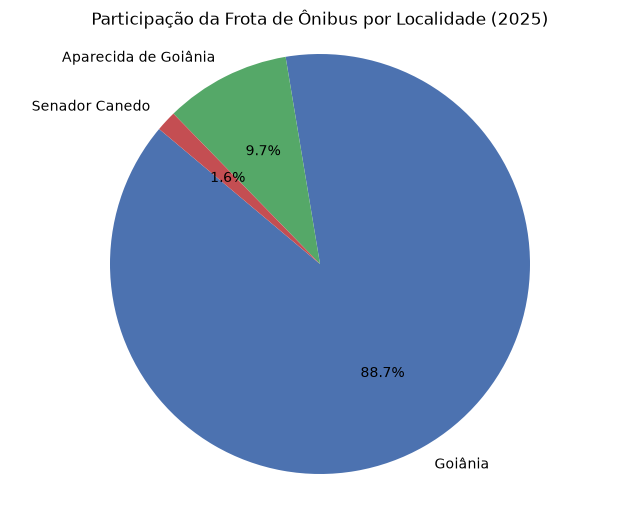

In [20]:
# Definir as variáveis para o gráfico com base na tabela do KPI 3
cidades = df_kpi3['Localidade']
percentagens = df_kpi3['Share da Frota (%)']

# Criar a figura do gráfico e definir o tamanho
plt.figure(figsize=(8, 6))

# Construir o gráfico circular (pie chart)
# autopct='%1.1f%%' formata os números para mostrar as percentagens com 1 casa decimal
plt.pie(percentagens, 
        labels=cidades, 
        autopct='%1.1f%%', 
        startangle=140, 
        colors=['#4C72B0', '#55A868', '#C44E52']) # Cores profissionais

# Adicionar um título claro
plt.title('Participação da Frota de Ônibus por Localidade (2025)')

# Garantir que o gráfico fica num círculo perfeito
plt.axis('equal') 

# Exibir o gráfico no ecrã
plt.show()